# Отчет по лабораторной работе №7 на тему "Классификация"

**Выполнил**: студент 3 курса группы 12002408

Рыбин Даниил Евгеньевич

**Проверил**: ассистент кафедры информационных и робототехнических систем

Пузырев Никита Сергеевич

Выполните следующие задания:

1. Откройте в файл в Google Colab (используйте собственный форк репозитория).
2. Решите задачи.
3. Сохраните результат в виде файла rep.ipynb в ваш репозиторий github в директорию ./les07
4. Создайте pull request в репозиторий https://github.com/chebotarevsa/dap-2024. Название pull request должно иметь формат "<Номер лабораторной работы>  <Номер группы> <ФИО>"
5. Сдайте работу в системе "Пегас", в отчет укажите ссылку на pull request

Используя набор данных titanic.csv постройте модель предсказывающую выжил или погиб пассажир.
1.	PassengerId – Идентификатор пассажира (уникальный номер для каждого пассажира).
2.	Survived – Выжил (0 – не выжил, 1 – выжил).
3.	Pclass – Класс пассажира (1 – первый класс, 2 – второй класс, 3 – третий класс).
4.	Name – Имя (полное имя пассажира).
5.	Sex – Пол (male – мужчина, female – женщина).
6.	Age – Возраст (числовое значение, может быть дробным).
7.	SibSp – Количество родственников на борту (братьев, сестер или супругов).
8.	Parch – Количество родителей или детей на борту.
9.	Ticket – Номер билета.
10.	Fare – Стоимость билета (в фунтах стерлингов).
11.	Cabin – Номер каюты (может быть пропущен, если данные отсутствуют).
12.	Embarked – Порт посадки (C – Cherbourg, Q – Queenstown, S – Southampton).

In [ ]:
import sys
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print(f"Python version: {sys.version}")
print(f"Numpy version: {np.version.version}")
print(f"Pandas version: {pd.__version__}")
print(f"Matplotlib version: {mpl.__version__}")

## Извлечение данных

1. Создайте DataFarame из файла titanic.csv, в качестве индекса используйте столбец "PassengerId".

In [51]:
import pandas as pd
df = pd.read_csv('data/titanic.csv', index_col='PassengerId')
print(df.head())

             Survived  Pclass  \
PassengerId                     
1                   0       3   
2                   1       1   
3                   1       3   
4                   1       1   
5                   0       3   

                                                          Name     Sex   Age  \
PassengerId                                                                    
1                                      Braund, Mr. Owen Harris    male  22.0   
2            Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0   
3                                       Heikkinen, Miss. Laina  female  26.0   
4                 Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0   
5                                     Allen, Mr. William Henry    male  35.0   

             SibSp  Parch            Ticket     Fare Cabin Embarked  
PassengerId                                                          
1                1      0         A/5 21171   7.2500   NaN        S

2. Выведете первые 7 строк набора.

In [52]:
print(df.head(7))

             Survived  Pclass  \
PassengerId                     
1                   0       3   
2                   1       1   
3                   1       3   
4                   1       1   
5                   0       3   
6                   0       3   
7                   0       1   

                                                          Name     Sex   Age  \
PassengerId                                                                    
1                                      Braund, Mr. Owen Harris    male  22.0   
2            Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0   
3                                       Heikkinen, Miss. Laina  female  26.0   
4                 Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0   
5                                     Allen, Mr. William Henry    male  35.0   
6                                             Moran, Mr. James    male   NaN   
7                                      McCarthy, Mr. Timothy J

### Подготовка данных

3. Выведете информацию о типах данных в наборе. Имеются ли в наборе не числовые признаки? Имеются ли в наборе данные имеющие значение null?
    

In [53]:
df.info()
not_num = df.select_dtypes(include='object').columns.tolist()
print("Нечисловые признаки:", not_num)
print(df.isnull().sum())
print("Есть null:", df.isnull().values.any())
print("Всего null:", df.isnull().sum().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    object 
 3   Sex       891 non-null    object 
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    object 
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    object 
 10  Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 83.5+ KB
Нечисловые признаки: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']
Survived      0
Pclass        0
Name          0
Sex           0
Age         177
SibSp         0
Parch         0
Ticket        0
Fare          0
Cabin       687
Embarked      2
dtype: int64
Есть null: True
Всего null: 866


4. Удалите не числовые признаки, которые по вашему мнению, не могут влиять на значение выжил или погиб пассажир.

In [54]:
df = df.drop(columns=['Name', 'Ticket', 'Cabin'])
print(df.columns.tolist())
print(df.head())

['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
             Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
PassengerId                                                                
1                   0       3    male  22.0      1      0   7.2500        S
2                   1       1  female  38.0      1      0  71.2833        C
3                   1       3  female  26.0      0      0   7.9250        S
4                   1       1  female  35.0      1      0  53.1000        S
5                   0       3    male  35.0      0      0   8.0500        S


5. Вместо признака "Sex" создайте два новых признака male и female которые содержат значения 0 или 1.

In [55]:
df['male']   = (df['Sex'] == 'male').astype(int)
df['female'] = (df['Sex'] == 'female').astype(int)
df = df.drop(columns=['Sex'])
print(df[['male', 'female']].head(10))
print(df.columns.tolist())

             male  female
PassengerId              
1               1       0
2               0       1
3               0       1
4               0       1
5               1       0
6               1       0
7               1       0
8               1       0
9               0       1
10              0       1
['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'male', 'female']


6. Удалите строки, которые содержать хотя бы одно null значение.

In [56]:
df = df.dropna()
print("Размер после удаления:", df.shape)
print("Пропусков осталось:", df.isnull().sum().sum())

Размер после удаления: (712, 9)
Пропусков осталось: 0


## Исследование данных

4. Нормализуйте значения признака "Fare".

In [57]:
df['Fare'] = (df['Fare'] - df['Fare'].min()) / (df['Fare'].max() - df['Fare'].min())
print(df['Fare'].describe())
print("Min:", df['Fare'].min())
print("Max:", df['Fare'].max())

count    712.000000
mean       0.067471
std        0.103329
min        0.000000
25%        0.015713
50%        0.030539
75%        0.064412
max        1.000000
Name: Fare, dtype: float64
Min: 0.0
Max: 1.0


5. Найдите разницу между средними значениями признака "Fare" для погибших и выживших пассажиров.

In [58]:
mean_died = df[df['Survived'] == 0]['Fare'].mean()
mean_survived = df[df['Survived'] == 1]['Fare'].mean()
diff = mean_survived - mean_died

print(f"Средний Fare погибших:  {mean_died:.4f}")
print(f"Средний Fare выживших:  {mean_survived:.4f}")
print(f"Разница (выжившие - погибшие): {diff:.4f}")

Средний Fare погибших:  0.0448
Средний Fare выживших:  0.1008
Разница (выжившие - погибшие): 0.0560


6. Простройте на одной оси координат гистограмы значений признака "Fare" для погибших и выживших пассажиров.

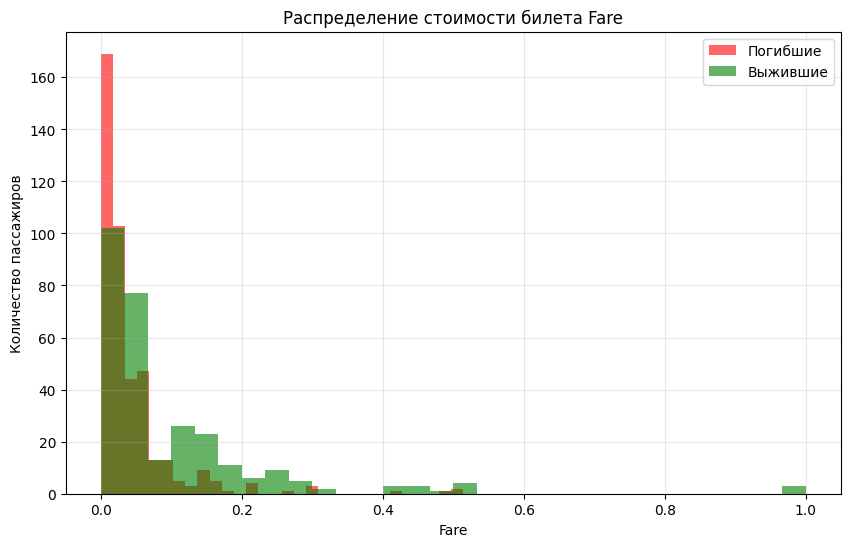

In [59]:
import matplotlib.pyplot as plt

fare_died     = df[df['Survived'] == 0]['Fare']
fare_survived = df[df['Survived'] == 1]['Fare']

plt.figure(figsize=(10, 6))

plt.hist(fare_died,     bins=30, alpha=0.6, label='Погибшие', color='red')
plt.hist(fare_survived, bins=30, alpha=0.6, label='Выжившие', color='green')

plt.xlabel('Fare')
plt.ylabel('Количество пассажиров')
plt.title('Распределение стоимости билета Fare')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

7. Сформируйте набор признаков (X). Сформируйте вектор целевых значений (y).

In [60]:
y = df['Survived']
X = df.drop(columns='Survived')

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nПризнаки X:")
print(X.columns.tolist())
print("\nстроки X:")
print(X.head())
print("\значения y:")
print(y.head())

X shape: (712, 8)
y shape: (712,)

Признаки X:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'male', 'female']

строки X:
             Pclass   Age  SibSp  Parch      Fare Embarked  male  female
PassengerId                                                             
1                 3  22.0      1      0  0.014151        S     1       0
2                 1  38.0      1      0  0.139136        C     0       1
3                 3  26.0      0      0  0.015469        S     0       1
4                 1  35.0      1      0  0.103644        S     0       1
5                 3  35.0      0      0  0.015713        S     1       0
\значения y:
PassengerId
1    0
2    1
3    1
4    1
5    0
Name: Survived, dtype: int64


## Предсказательная модель

8. Разделите набор данных на два, одни для обучения модели другой для проверки. Тестовый набор должен содержать 25 процентов данных.

In [61]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (534, 8) | X_test: (178, 8)
y_train: (534,) | y_test: (178,)


9. Выполните обучение модели.

In [62]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

y = df['Survived']
X = df.drop(columns='Survived')
X = pd.get_dummies(X, columns=['Embarked'], prefix='Embarked')
print("Нечисловые столбцы:", X.select_dtypes(include='object').columns.tolist())
print("Столбцы X:", X.columns.tolist())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("X_train:", X_train.shape, " X_test:", X_test.shape)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("\nAccuracy: ", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:   ", round(recall_score(y_test, y_pred), 4))
print("F1-score: ", round(f1_score(y_test, y_pred), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))

print(classification_report(y_test, y_pred,
                            target_names=['Погиб', 'Выжил']))

Нечисловые столбцы: []
Столбцы X: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'male', 'female', 'Embarked_C', 'Embarked_Q', 'Embarked_S']
X_train: (534, 10)  X_test: (178, 10)

Accuracy:  0.7697
Precision: 0.7313
Recall:    0.6806
F1-score:  0.705

Confusion matrix:
[[88 18]
 [23 49]]
              precision    recall  f1-score   support

       Погиб       0.79      0.83      0.81       106
       Выжил       0.73      0.68      0.71        72

    accuracy                           0.77       178
   macro avg       0.76      0.76      0.76       178
weighted avg       0.77      0.77      0.77       178



## Проверка модели

10. Выведите мартицу ошибок

Матрица ошибок:
[[88 18]
 [23 49]]

Матрица ошибок:
             Прогноз: Погиб  Прогноз: Выжил
Факт: Погиб              88              18
Факт: Выжил              23              49


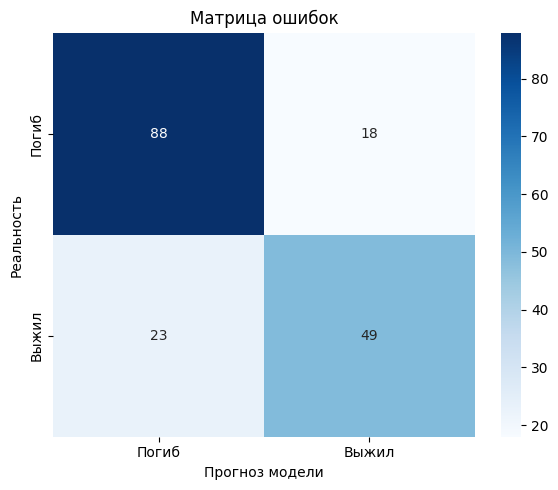

In [63]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)
print("Матрица ошибок:")
print(cm)

cm_df = pd.DataFrame(
    cm,
    index=['Факт: Погиб', 'Факт: Выжил'],
    columns=['Прогноз: Погиб', 'Прогноз: Выжил']
)
print("\nМатрица ошибок:")
print(cm_df)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Погиб', 'Выжил'],
    yticklabels=['Погиб', 'Выжил']
)
plt.xlabel('Прогноз модели')
plt.ylabel('Реальность')
plt.title('Матрица ошибок')
plt.tight_layout()
plt.show()

11. Расчитайте accuracy

In [64]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.7697


12. Сделайте вывод о полученном результате

Вывод: Модель логистической регрессии показала точность = 0.77 (77%). Это означает, что из 178 пассажиров тестовой выборки модель правильно предсказала исход для 137 человек и ошиблась в 41 случае. Результат удовлетворительный.

## Вопросы для защиты

**1. Сформулируйте задачу классификации.**

Задача классификации - это задача машинного обучения с учителем, в которой по набору признаков объекта нужно предсказать его принадлежность к одному из заранее известных классов (дискретных категорий). Модель обучается на размеченных данных (X, y) и находит решающую функцию, отображающую признаки в метку класса.

**2. Перечислите типы классификации.**

- Бинарная - два класса (0/1, да/нет).
- Мультиклассовая - три и более взаимоисключающих класса.
- Многометочная (multi-label) - объект может принадлежать нескольким классам одновременно.
- Несбалансированная - классы представлены неравномерно.
- Одноклассовая (one-class) - только один класс + аномалии.

**3. В чем особенность несбалансированной классификации?**

Классы представлены неравномерно: один встречается значительно чаще других (например, 99% против 1%). Особенности:
- Модель «склоняется» к мажоритарному классу.
- Точность становится обманчивой метрикой.

**4. В чем особенность мультиклассовой классификации?**

- Каждый объект принадлежит ровно одному из трёх и более классов.
- Модели изначально бинарные

**5. В чем особенность бинарной классификации?**

- Всего два класса (0/1, положительный/отрицательный).
- Простейшая, но требует выбора порога.
- Возможен дисбаланс классов.

**6. В чем особенность классификации по нескольким меткам?**

- Объект может принадлежать нескольким классам одновременно
- Метки не взаимоисключающие.
- Для каждой метки обучается отдельный бинарный классификатор.

**7. Чем стратегия «Один против всех» отличается от стратегии «Один против одного»?**

- Число моделей: OvR — K, OvO — K(K−1)/2.
- Обучающая выборка: OvR - весь набор (с дисбалансом), OvO - только объекты двух классов (сбалансированно).
- Способ решения: OvR - по максимальной вероятности, OvO - по большинству голосов.
- Применение: OvR - при большом числе классов (быстрее), OvO - при сильном дисбалансе и малом числе классов (точнее).

**8. Что такое матрица ошибок (несоответствий)?**

Таблица, показывающая, сколько объектов попало в каждую категорию.

**9. Как рассчитывается Accuracy?**

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

Где:
- TN - верно предсказан отрицательный класс.
- TP - верно предсказан положительный класс.
- FP - ложное срабатывание (ошибка I рода).
- FN - пропуск (ошибка II рода).

**10. Объясните алгоритм классификации K-ближайших соседей.**

KNN (K-Nearest Neighbors)- метрический алгоритм, основанный на ленивом обучении (нет явной фазы обучения — данные просто запоминаются).

Алгоритм:
1. Выбрать число K (количество соседей) и метрику расстояния.
2. Для нового объекта вычислить расстояние до всех обучающих объектов.
3. Отобрать K ближайших соседей.
4. Для классификации - голосование: класс = самый частый среди K соседей.
5. Для регрессии - среднее значений соседей.
